# Lab 6: Random Forest for Classification

**Name:** Yashodhara Heggade  
**Reg:** 2427010154  
**Sec:** C/ Batch 1

## Objective
Build a Random Forest classifier using a sample dataset. Study the effect of changing (a) the maximum tree depth and (b) the number of trees, and compare accuracy, precision, and recall with graphs.

## Dataset: Kaggle Breast Cancer Wisconsin (Diagnostic)


## 1. Import libraries


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

## 2. Load and inspect the Kaggle data


In [2]:
csv_candidates = [
    Path("/kaggle/input/breast-cancer-wisconsin-data/data.csv"),
    Path("data.csv"),
    Path("data/data.csv")
]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find data.csv. Download it from the Kaggle dataset page and place it "
        "beside this notebook (or in ./data/data.csv). On Kaggle, attach the dataset so "
        "it is available under /kaggle/input/breast-cancer-wisconsin-data/."
    )

df = pd.read_csv(csv_path)
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

print("Loaded file:", csv_path)
print("Dataset shape after removing identifier/empty columns:", df.shape)
print("Number of input features:", df.shape[1] - 1)
print("\nClass counts (B = benign, M = malignant):")
print(df["diagnosis"].value_counts())
df.head()

Loaded file: data.csv
Dataset shape after removing identifier/empty columns: (569, 31)
Number of input features: 30

Class counts (B = benign, M = malignant):
diagnosis
B    357
M    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Split the data into training and testing sets

In [3]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 455
Testing records: 114


## 4. Evaluation function


In [4]:
def evaluate_model(model):
    predictions = model.predict(X_test)
    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (malignant)": precision_score(
            y_test, predictions, pos_label="M", zero_division=0
        ),
        "Recall (malignant)": recall_score(
            y_test, predictions, pos_label="M", zero_division=0
        )
    }

## 5. Experiment A: Try different maximum tree depths

`max_depth` controls how many levels each tree can grow. Smaller depths make simpler trees; `None` lets a tree grow until other stopping conditions are met. We keep the number of trees fixed at 100 while varying depth.

In [5]:
depth_values = [1, 2, 3, 5, 8, None]
depth_results = []

for depth in depth_values:
    model = RandomForestClassifier(
        n_estimators=100, max_depth=depth,
        random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    scores = evaluate_model(model)
    depth_results.append({
        "Maximum depth": "Unlimited" if depth is None else depth,
        **scores
    })

depth_df = pd.DataFrame(depth_results)
depth_df.round(3)

,Maximum depth,Accuracy,Precision (malignant),Recall (malignant)
0,1,0.912,1.000,0.762
1,2,0.947,0.974,0.881
2,3,0.956,1.000,0.881
3,5,0.974,1.000,0.929
4,8,0.974,1.000,0.929
5,Unlimited,0.974,1.000,0.929


### Graph: metrics for different tree depths

A higher score indicates better performance for that metric on this test split.

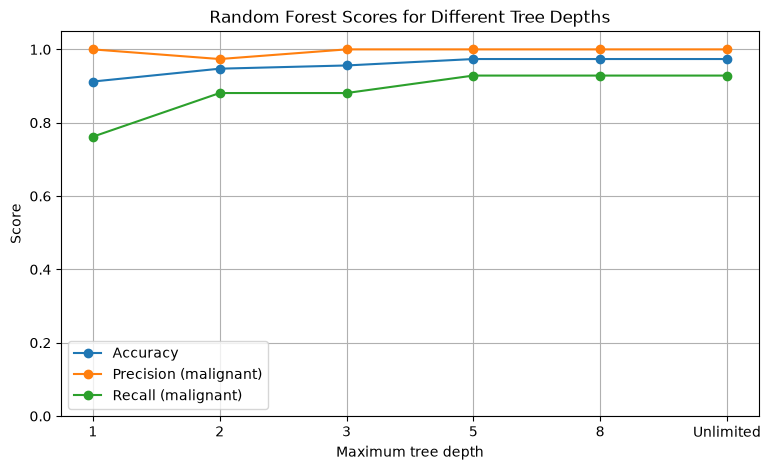

In [6]:
plt.figure(figsize=(9, 5))
for metric in ["Accuracy", "Precision (malignant)", "Recall (malignant)"]:
    plt.plot(depth_df["Maximum depth"].astype(str), depth_df[metric], marker="o", label=metric)

plt.xlabel("Maximum tree depth")
plt.ylabel("Score")
plt.title("Random Forest Scores for Different Tree Depths")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

## 6. Experiment B: Try different numbers of trees

`n_estimators` is the number of decision trees in the forest. Here the depth is kept unlimited while we vary the number of trees. More trees may make predictions more stable, but they also require more computation.

In [7]:
tree_values = [1, 5, 10, 25, 50, 100, 200]
tree_results = []

for number_of_trees in tree_values:
    model = RandomForestClassifier(
        n_estimators=number_of_trees, max_depth=None,
        random_state=42, n_jobs=-1
    )
    model.fit(X_train, y_train)
    scores = evaluate_model(model)
    tree_results.append({"Number of trees": number_of_trees, **scores})

tree_df = pd.DataFrame(tree_results)
tree_df.round(3)

,Number of trees,Accuracy,Precision (malignant),Recall (malignant)
0,1,0.956,0.974,0.905
1,5,0.965,0.975,0.929
2,10,0.965,1.000,0.905
3,25,0.965,0.975,0.929
4,50,0.974,1.000,0.929
5,100,0.974,1.000,0.929
6,200,0.965,1.000,0.905


### Graph: metrics for different numbers of trees

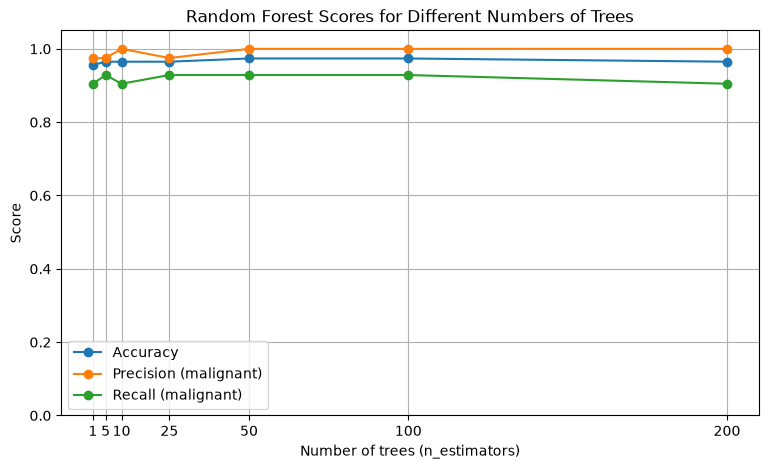

In [8]:
plt.figure(figsize=(9, 5))
for metric in ["Accuracy", "Precision (malignant)", "Recall (malignant)"]:
    plt.plot(tree_df["Number of trees"], tree_df[metric], marker="o", label=metric)

plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Score")
plt.title("Random Forest Scores for Different Numbers of Trees")
plt.xticks(tree_values)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

## 7. Compare the metric tables


In [9]:
print("Metrics by maximum tree depth:")
display(depth_df.round(3))

print("Metrics by number of trees:")
display(tree_df.round(3))

Metrics by maximum tree depth:


,Maximum depth,Accuracy,Precision (malignant),Recall (malignant)
0,1,0.912,1.000,0.762
1,2,0.947,0.974,0.881
2,3,0.956,1.000,0.881
3,5,0.974,1.000,0.929
4,8,0.974,1.000,0.929
5,Unlimited,0.974,1.000,0.929


Metrics by number of trees:


,Number of trees,Accuracy,Precision (malignant),Recall (malignant)
0,1,0.956,0.974,0.905
1,5,0.965,0.975,0.929
2,10,0.965,1.000,0.905
3,25,0.965,0.975,0.929
4,50,0.974,1.000,0.929
5,100,0.974,1.000,0.929
6,200,0.965,1.000,0.905
